# One feedback choice for two-point and three-point shear

Gas cooling and energetic outflows move matter inside and around halos. The
power spectrum and the bispectrum weight that redistribution differently, so a
feedback model must answer for both statistics at once. This notebook switches on
**the BACCO paired response**, one ratio for the power spectrum and one for the
bispectrum from the same five feedback parameters, and propagates them through
the same DES Y3 joint prediction.

The ratios come from the Burger2025 BACCO emulators, trained on simulations of
cold matter; the theory block converts them to total matter under a declared
neutrino assumption. The feedback values below are examples inside the training
range, not a fit to DES.
[Paired-response description](../../external_modules/code/cosmolike_core/cosmolike/3pcf/README.md#paired-feedback) lists public paired sources and explains the
cold-matter/total-matter distinction. The
[project acknowledgements](README.md#acknowledgements) credit the original
fastnc code and the calculations of Sugiyama and Gomes.

The cells build their Cobaya models from `EXAMPLE_EVALUATE3.yaml`; they need the installed BACCO weights and write only figures to `chains/`. The source distribution and released survey covariance remain inputs in `data/`.


**Model and data.** The settings come from the numbered example yaml that the
cells below load:

| Choice | Value |
| --- | --- |
| Configuration | `EXAMPLE_EVALUATE3.yaml`, with its commented BACCO blocks switched on |
| Response pair | the `bacco_bispectrum` theory block (Burger2025 BACCO emulators) |
| Feedback points | `M_c_baccoemu` $= 13$, $14$, $15$; the other four BACCO parameters at the yaml's values |
| Data vector | 400 two-point rows and 80 aperture rows, all kept |
| Figures | source pair (1,1) and source triple (1,1,1); files in `chains/joint_feedback/` |
| Threads | one BLAS worker; OpenMP capped at four |

Words used throughout:

- **DMO**, dark-matter-only: the gravity-only reference model, with no baryonic
  feedback applied to its power spectrum or bispectrum.
- A **response table** stores a ratio such as
  $R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$ on a
  wavenumber-redshift grid; multiplying the DMO prediction by the table applies
  the feedback model.
- `M_c_baccoemu` $=\log_{10}[M_c/(h^{-1}M_\odot)]$ is BACCO's halo mass scale
  governing how much gas a halo keeps.
- $\xi_\pm(\theta)$ are the two-point shear correlations at angular separation
  $\theta$; $\langle M_\mathrm{ap}^3(R)\rangle$ is the **aperture skewness**, the
  third moment of shear integrated with a compensated filter of radius $R$.
- **NLA**, the nonlinear-alignment model: the intrinsic-alignment model of
  `EXAMPLE_EVALUATE3.yaml`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib
import copy

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
# BACCO uses JAX for its small emulator calls; no GPU is requested.
os.environ["JAX_PLATFORMS"] = "cpu"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
from cobaya.yaml import yaml_load_file
from cobaya.model import get_model

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. The response pair and its limits

The likelihood multiplies the gravity-only spectra by the two ratios,
$P=R_P\,P_\mathrm{DMO}$ and $B=R_B\,B_\mathrm{DMO}$, with $R_P$ and $R_B$ from
the same BACCO feedback parameters; no relation between $R_B$ and $R_P$ is
assumed. The values $13\le$ `M_c_baccoemu` $\le15$ lie inside the installed
training range $10.01$ to $16.00$, and the other four parameters and the
yaml's cosmology lie inside theirs (see the
[BACCO theory guide](../../external_modules/code/cosmolike_core/theory/bacco_bispectrum/README.md)).

The feedback assumption modifies only the nonlinear-alignment baseline of the
IA model; the quadratic IA corrections keep their DMO spectra in both
statistics. This matches how the ordinary CFASTPT calculation, the C port of
the FAST-PT perturbation-theory code, separates its nonlinear baseline from its
linear-power loop corrections. The fixed Y3 covariance stays the configured
input, so the feedback changes the mean prediction only.

In [3]:
# The numbered example EXAMPLE_EVALUATE3.yaml; its paths are relative to the
# Cocoa folder, hence the change of working directory. point = the parameter
# values Cobaya's evaluate sampler would run (the yaml's override block).
os.chdir(PROJECT.parents[1])
information = yaml_load_file(str(PROJECT / "EXAMPLE_EVALUATE3.yaml"))
point = dict(information["sampler"]["evaluate"]["override"])
information.pop("sampler")
information.pop("output", None)

# The gravity-only (DMO) model: the yaml as it is, with the BiHalofit bispectrum.
gravity_only = get_model(information)

# The feedback model: the yaml's commented BACCO blocks switched on. The
# likelihood then requests the paired ratios R_P and R_B, which the
# bacco_bispectrum theory block computes from CAMB's spectra and five baryonic
# correction model parameters. M_c_baccoemu varies below; its prior is the
# installed training range. The other four keep the yaml's example values.
feedback_information = copy.deepcopy(information)
likelihood_options = feedback_information["likelihood"]["des_3pcf.joint_shear"]
likelihood_options["external_baryon_response"] = True
feedback_information["theory"]["bacco_bispectrum"] = {
    "response_settings": {
        "neutrino_model": "coherent_linear_neutrinos",
        "low_k_anchor": 0.02,
        "high_k_anchor": 10.0,
        "high_k_mode": "shape_preserving",
        "high_z_mode": "hold",
        "nz": 17,
        "nk": 97,
        "nu": 33,
        "nv": 9,
        "boost": 2,
    },
    "zmax": 3.1,
    "kmax_boltzmann": 5.0,
}
feedback_information["params"].update({
    "M_c_baccoemu": {"prior": {"min": 10.01, "max": 15.99}, "ref": 14.0},
    "eta_baccoemu": -0.3,
    "beta_baccoemu": -0.22,
    "M1_z0_cen_baccoemu": 10.5,
    "theta_inn_baccoemu": -0.86,
})
with_feedback = get_model(feedback_information)
rows = with_feedback.likelihood["des_3pcf.joint_shear"].rows
mass_scales = (13.0, 14.0, 15.0)
print("Joint rows:", rows.values.size)


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


Joint rows: 480


## 2. Change feedback without rerunning CAMB

Only a BACCO parameter changes between the feedback points, so Cobaya keeps its
CAMB result and recomputes the response pair and the projection. A
gravity-only model of the same yaml, evaluated before the feedback points and
again after them, must reproduce its first prediction exactly; the cell checks
that no feedback-modified state survives in the shared native code.

All 400 two-point and 80 aperture rows stay present. The prediction keeps the
inputs of `EXAMPLE_EVALUATE3.yaml`, so its source clipping, estimator and
accuracy limits carry over unchanged.

In [4]:
# Gravity-only prediction first: every row of the joint data vector.
# cached=False: Cobaya serves a revisited point from its cache without
# running the likelihood, and last_datavector would keep the previous
# point's vector; each call here must refresh it.
gravity_only.logposterior(point, cached=False)
reference = np.array(
    gravity_only.likelihood["des_3pcf.joint_shear"].last_datavector, copy=True,
)

# The paired response at each mass scale; only a BACCO parameter changes.
means = []
for mass_scale in mass_scales:
    posterior = with_feedback.logposterior(dict(point, M_c_baccoemu=mass_scale),
                                           cached=False)
    if not np.isfinite(posterior.logpost):
        raise RuntimeError(f"BACCO rejected M_c_baccoemu = {mass_scale}.")
    means.append(np.array(
        with_feedback.likelihood["des_3pcf.joint_shear"].last_datavector, copy=True,
    ))
metadata = with_feedback.provider.get_result("baryon_response")["metadata"]
print("Response producer:", metadata["producer"], "; source:", metadata["source_url"])
print("Massive-neutrino fraction of the matter density:", metadata["neutrino_fraction"])

# Feedback off again: the gravity-only model, with Cobaya's cache off, must
# reproduce its first prediction bit for bit after the feedback evaluations.
gravity_only.logposterior(point, cached=False)
restored = gravity_only.likelihood["des_3pcf.joint_shear"].last_datavector
np.testing.assert_array_equal(restored, reference)
print("All joint rows:", rows.values.size)
print("DMO prediction restored exactly; CAMB reused for every feedback point:", True)


Response producer: dynamic_bacco ; source: https://arxiv.org/abs/2506.18974
Massive-neutrino fraction of the matter density: 0.004280538424074854


All joint rows: 480
DMO prediction restored exactly; CAMB reused for every feedback point: True


## 3. Compare the observable responses

The plots show the first source auto-correlation for readability; the
calculation keeps all rows. The vertical coordinate is the percentage change
from the DMO prediction at each angular bin. $\xi_+$, $\xi_-$ and the aperture
skewness respond with different shapes because each statistic weights the
Fourier modes differently and the power and bispectrum ratios are independent
inputs. Shape differences of this kind can help a joint fit, but their size
alone is not a Fisher gain: that calculation also needs the nuisance parameters
and the cross-covariance.

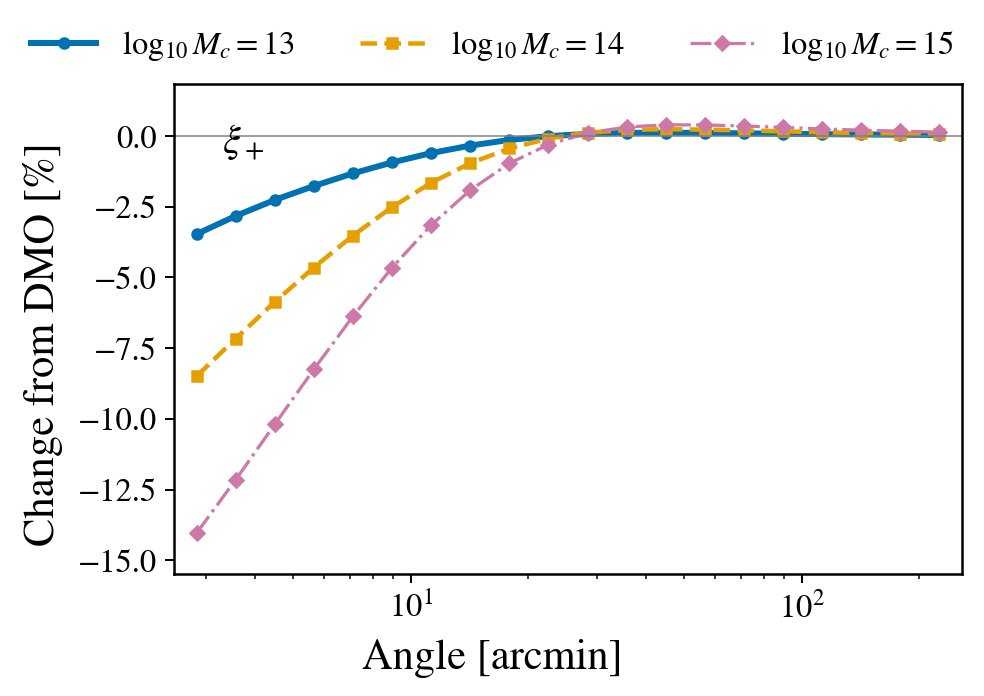

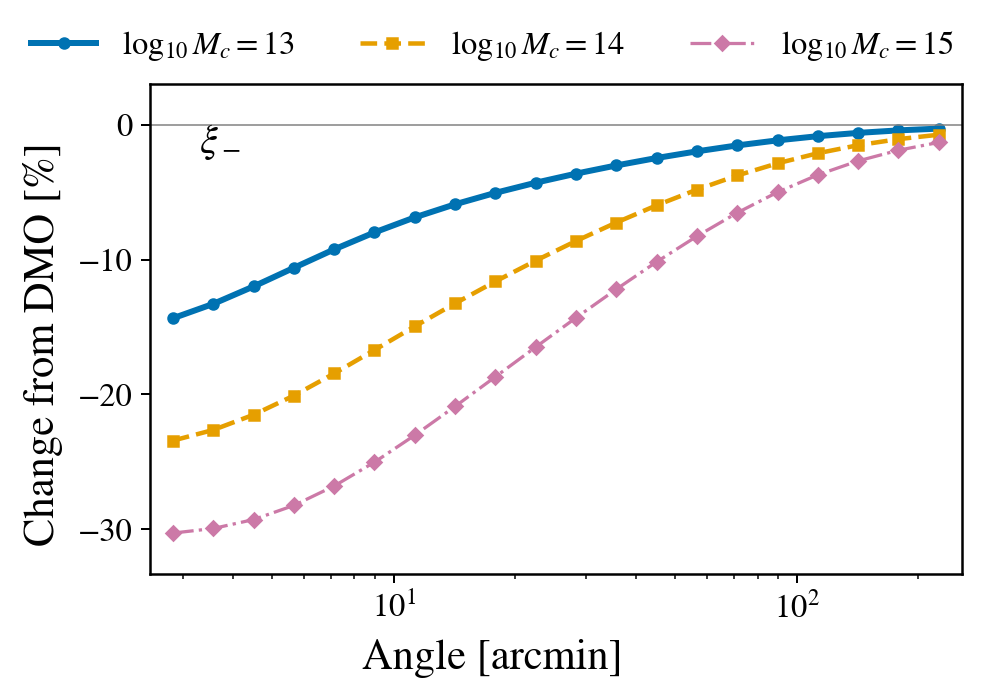

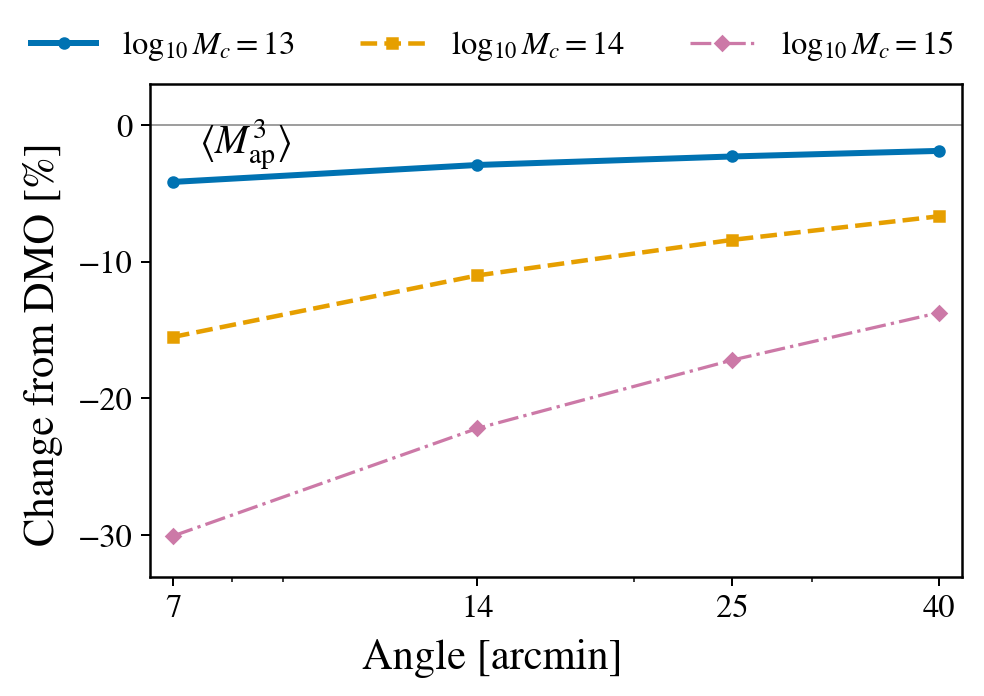

In [5]:
output = PROJECT / "chains/joint_feedback"
output.mkdir(parents=True, exist_ok=True)
for kind, label in (("xip", r"$\xi_+$"), ("xim", r"$\xi_-$"),
                    ("map3", r"$\langle M_{\rm ap}^3\rangle$")):
    selected = (rows.kind == kind) & (rows.bins[:, 0] == 0)
    selected &= rows.bins[:, 1] == 0
    if kind == "map3":
        selected &= rows.bins[:, 2] == 0
        angles = rows.angles[selected, 0]
    else:
        angles = rows.angles[selected, 2]
    angles = angles * 180. * 60. / np.pi
    curves = []
    for values in means:
        relative = 100. * (values[selected] / reference[selected] - 1.)
        curves.append((angles, relative[None, :]))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[label],
        coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
        legend=[rf"$\log_{{10}}M_c={value:.0f}$" for value in mass_scales],
        marker=["o", "s", "D"], linewidth=[2.4, 1.8, 1.3],
        linestyle=["-", "--", "-."],
        ncols=1, figsize=(5.3, 3.8), show=None,
    )
    # Finish constrained layout before measuring the exported labels.
    figure.canvas.draw()
    figure.savefig(output / f"feedback_{kind}.png", dpi=150,
                   bbox_inches="tight", pad_inches=0.2)
    plt.show()


## 4. Use a physical pair for an inference study

Sampling the five BACCO parameters needs priors inside the training box,
including the cosmology coordinates $\Omega_c$, $\Omega_b$ and $\sigma_{8,c}$; the
numbered MCMC and Nautilus yamls carry the same commented blocks. The theory
block recomputes both ratios at every cosmology, and its conversion from cold to
total matter is a declared assumption, not an identity.

The native tests vary constant $R_P$ and $R_B$ independently, check the
amplitude law, permute scalene triangles, change the preparation resolution and
restore state. They also verify that the actual CFASTPT quadratic terms and the
projected higher-order IA components stay fixed under this model. The pair
changes neither the ordinary core C files nor the separately specified
covariance prescription.